# GNSS IQ worked example: scene → acquire → track (kshana 0.32.0)

This notebook drives the GNSS IQ layer of the **published** `kshana` wheel
(`pip install kshana==0.32.0`) end to end, with no Rust toolchain:

1. **`kshana.iq_scene`** synthesises 2 s of complex baseband GPS L1 C/A IQ for three satellites
   with thermal noise, plus a per-epoch truth table (code phase, Doppler, C/N0).
2. **`kshana.iq_acquire`** runs FFT acquisition on four PRNs (three present, one absent).
3. The acquisition **search grid** of one PRN is plotted (recomputed in NumPy, see note in §3).
4. **`kshana.iq_track`** acquires and then runs the DLL/PLL/FLL bank; we plot Doppler,
   C/N0 and lock indicators against the scene's injected truth.
5. A short sensitivity sweep: the acquisition statistic against its threshold as C/N0 falls.

Everything is seeded, so re-running gives the same numbers. The scene is **synthetic** — this
is a demonstration of the API and its truth-recovery behaviour, not a validation on a real
capture. To process a real recording instead, load its I and Q as float lists (e.g. with
`numpy.fromfile`) and pass them to `iq_acquire` / `iq_track` with its sample rate and IF.

In [1]:
import platform, sys, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import kshana

print("kshana     ", kshana.version())
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)
print("python     ", sys.version.split()[0], "on", platform.platform())
assert kshana.version() == "0.32.0", "this notebook is pinned to the 0.32.0 wheel"
print("signals:", ", ".join(kshana.iq_signals()))

# Chart styling: recessive axes, thin marks, a fixed categorical order per PRN.
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6,
    "font.size": 9.5,
})
COLOR = {3: "#2a78d6", 11: "#eb6834", 22: "#1baf7a"}   # blue, orange, aqua
INK2 = '#52514e'

kshana      0.32.0
numpy       2.5.3
matplotlib  3.11.2
python      3.13.16 on Linux-6.18.44-fc-v77-x86_64-with-glibc2.39
signals: gps-l1ca, gps-l5i, gps-l5q, gps-l2c, galileo-e1b, galileo-e1c, galileo-e5a-i, galileo-e5a-q, beidou-b1i, beidou-b1c, glonass-l1of


## 1. Synthesise a scene

4.092 MHz complex sampling (4 samples per C/A chip), zero IF, three satellites at fixed
Dopplers, 45 dB-Hz, receiver thermal noise on. `iq_scene` returns the samples as two float
lists and a truth list with one row per satellite per 1 ms epoch.

In [2]:
FS = 4.092e6
PRNS = [3, 11, 22]
DOPPLERS = [1250.0, -2300.0, 400.0]
CN0 = 45.0

t0 = time.perf_counter()
scene = kshana.iq_scene(fs_hz=FS, duration_s=2.0, signal="gps-l1ca", prns=PRNS,
                        dopplers=DOPPLERS, cn0_dbhz=CN0, seed=7)
print(f"iq_scene: {len(scene['samples_i']):,} complex samples in {time.perf_counter()-t0:.1f} s; "
      f"centre {scene['center_hz']/1e6:.3f} MHz, IF {scene['if_hz']} Hz")

truth = scene["truth"]
truth0 = {r["sat_id"]: r for r in truth if r["t_s"] == 0.0}
print(f"{'PRN':>4} {'Doppler Hz':>11} {'code phase chips':>17} {'C/N0 dB-Hz':>11}")
for p in PRNS:
    r = truth0[p]
    print(f"{p:>4} {r['doppler_hz']:>11.1f} {r['code_phase_chips']:>17.3f} {r['cn0_dbhz']:>11.1f}")
# Note: iq_scene places every satellite on the same default range profile, so the three
# code phases are close; the codes themselves are orthogonal, so acquisition separates them.

iq_scene: 8,184,000 complex samples in 8.3 s; centre 1575.420 MHz, IF 0.0 Hz
 PRN  Doppler Hz  code phase chips  C/N0 dB-Hz
   3      1250.0           293.786        45.0
  11     -2300.0           293.078        45.0
  22       400.0           292.370        45.0


## 2. Acquire

`iq_acquire` searches each PRN over the default Doppler window and reports the peak cell, the
detection statistic and the threshold set from the search-wide false-alarm probability. PRN 5
is **not** in the scene and must not be acquired.

In [3]:
I, Q = scene["samples_i"], scene["samples_q"]
SEARCH = PRNS + [5]
t0 = time.perf_counter()
acq = kshana.iq_acquire(I[: int(FS * 0.02)], Q[: int(FS * 0.02)], FS, "gps-l1ca", SEARCH,
                        if_hz=scene["if_hz"])
print(f"iq_acquire over 20 ms, {len(SEARCH)} PRNs: {time.perf_counter()-t0:.2f} s\n")
print(f"{'PRN':>4} {'acq':>5} {'stat':>7} {'thresh':>7} {'Doppler':>9} {'truth':>8} "
      f"{'code ph':>8} {'truth':>8}")
for p, d in zip(SEARCH, acq):
    tr = truth0.get(p)
    print(f"{p:>4} {str(d['acquired']):>5} {d['statistic']:>7.1f} {d['threshold']:>7.1f} "
          f"{d['doppler_hz']:>9.1f} {tr['doppler_hz'] if tr else float('nan'):>8.1f} "
          f"{d['code_phase_chips']:>8.2f} {tr['code_phase_chips'] if tr else float('nan'):>8.2f}")

for p, d in zip(SEARCH, acq):
    if p in truth0:
        assert d["acquired"], p
        # Coarse search: Doppler within one bin, code phase within half a chip of the truth.
        assert abs(d["doppler_hz"] - truth0[p]["doppler_hz"]) < 700, p
        dc = (d["code_phase_chips"] - truth0[p]["code_phase_chips"] + 511.5) % 1023 - 511.5
        assert abs(dc) <= 0.5, p
    else:
        assert not d["acquired"], p
print("\nall present PRNs acquired near the truth; the absent PRN was rejected")

iq_acquire over 20 ms, 4 PRNs: 0.10 s

 PRN   acq    stat  thresh   Doppler    truth  code ph    truth
   3  True    50.6    35.9    1333.3   1250.0   293.75   293.79
  11  True    44.5    35.9   -2666.7  -2300.0   293.00   293.08
  22  True    56.0    35.9     666.7    400.0   292.25   292.37
   5 False    23.4    35.9    3333.3      nan   525.50      nan

all present PRNs acquired near the truth; the absent PRN was rejected


## 3. The acquisition grid

`iq_acquire` returns the decision, not the full search surface, so for the picture we recompute
the code-phase × Doppler grid in NumPy: a noise-free 1 ms PRN-3 replica is generated **by kshana
itself** (`iq_scene(..., noise=False)`), and each Doppler bin is the FFT circular correlation of
the recording with that replica, non-coherently summed over 10 ms. The kshana detection is
marked on top; the two must agree.

grid peak: Doppler 1250 Hz, code phase 293.79 chips, 15.3 dB over the median cell
iq_acquire: Doppler 1333 Hz, code phase 293.75 chips
truth:      Doppler 1250 Hz, code phase 293.79 chips


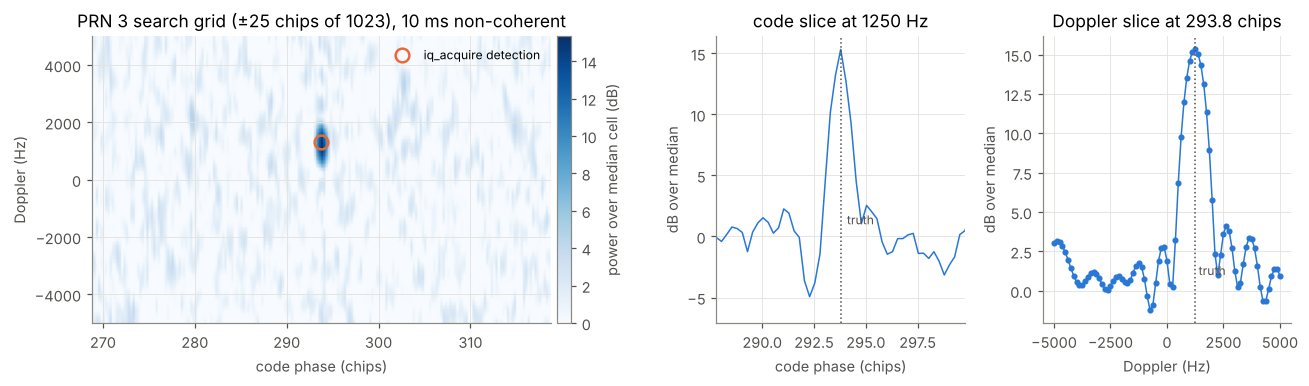

In [4]:
N = int(FS * 1e-3)                       # samples per 1 ms code period
rep = kshana.iq_scene(fs_hz=FS, duration_s=0.001, signal="gps-l1ca", prns=[3],
                      dopplers=[0.0], noise=False, seed=1)
rep_phase = rep["truth"][0]["code_phase_chips"]
R = np.conj(np.fft.fft(np.asarray(rep["samples_i"][:N]) + 1j * np.asarray(rep["samples_q"][:N])))

x = np.asarray(I[: 10 * N]) + 1j * np.asarray(Q[: 10 * N])
t = np.arange(N) / FS
fd = np.arange(-5000.0, 5000.1, 125.0)
grid = np.zeros((fd.size, N))
for k in range(10):
    blk = x[k * N:(k + 1) * N]
    ph = np.exp(-2j * np.pi * np.outer(fd, t + k * 1e-3))
    grid += np.abs(np.fft.ifft(np.fft.fft(blk[None, :] * ph, axis=1) * R, axis=1)) ** 2
grid /= np.median(grid)                   # normalise to the noise floor

# corr[l] = sum_n x[n+l] conj(r[n]) peaks where the signal's code phase is rep_phase - l*R/fs.
code_axis = (rep_phase - np.arange(N) * 1.023e6 / FS) % 1023
order = np.argsort(code_axis)
code_axis, grid_s = code_axis[order], grid[:, order]

ib, il = np.unravel_index(grid_s.argmax(), grid_s.shape)
a3 = acq[SEARCH.index(3)]
print(f"grid peak: Doppler {fd[ib]:.0f} Hz, code phase {code_axis[il]:.2f} chips, "
      f"{10*np.log10(grid_s.max()):.1f} dB over the median cell")
print(f"iq_acquire: Doppler {a3['doppler_hz']:.0f} Hz, code phase {a3['code_phase_chips']:.2f} chips")
print(f"truth:      Doppler {truth0[3]['doppler_hz']:.0f} Hz, code phase {truth0[3]['code_phase_chips']:.2f} chips")
assert abs(code_axis[il] - a3["code_phase_chips"]) < 1.0

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1]})
im = axs[0].imshow(10 * np.log10(grid_s), aspect="auto", origin="lower", cmap="Blues",
                   extent=[code_axis[0], code_axis[-1], fd[0], fd[-1]], vmin=0)
axs[0].plot(a3["code_phase_chips"], a3["doppler_hz"], marker="o", ms=9, mfc="none",
            mec="#eb6834", mew=1.6, ls="none", label="iq_acquire detection")
axs[0].set(xlabel="code phase (chips)", ylabel="Doppler (Hz)",
           xlim=(code_axis[il] - 25, code_axis[il] + 25),
           title="PRN 3 search grid (±25 chips of 1023), 10 ms non-coherent")
axs[0].legend(loc="upper right", fontsize=8, frameon=False)
fig.colorbar(im, ax=axs[0], label="power over median cell (dB)", pad=0.01)

axs[1].plot(code_axis, 10 * np.log10(grid_s[ib]), color=COLOR[3], lw=1)
axs[1].set(xlim=(code_axis[il] - 6, code_axis[il] + 6), xlabel="code phase (chips)",
           ylabel="dB over median", title=f"code slice at {fd[ib]:.0f} Hz")
axs[1].axvline(truth0[3]["code_phase_chips"], color=INK2, ls=":", lw=1)
axs[1].text(truth0[3]["code_phase_chips"] + 0.3, 1, "truth", color=INK2, fontsize=8)

axs[2].plot(fd, 10 * np.log10(grid_s[:, il]), color=COLOR[3], marker="o", ms=3, lw=1)
axs[2].set(xlabel="Doppler (Hz)", ylabel="dB over median",
           title=f"Doppler slice at {code_axis[il]:.1f} chips")
axs[2].axvline(truth0[3]["doppler_hz"], color=INK2, ls=":", lw=1)
axs[2].text(truth0[3]["doppler_hz"] + 150, 1, "truth", color=INK2, fontsize=8)
fig.tight_layout()
plt.show()

## 4. Track

`iq_track` acquires each PRN, then runs the tracking bank (default GPS-L1-C/A-like loop design:
FLL-assisted PLL, DLL, NWPR and Beaulieu C/N0 estimators, bit synchronisation) and returns one
row per 1 ms epoch per channel.

**Use a finer acquisition before tracking.** With the default `acq_coherent=1` the hand-off
search steps Doppler in 2/(3·1 ms) ≈ 667 Hz bins, so the initial carrier error can reach
≈ 333 Hz — beyond the ≈ 250 Hz pull-in of a 1 ms FLL. On this scene that makes two of the
three channels settle on a false lock ≈ 500 Hz off (shown in the next cell). `acq_coherent=2`
halves the bin and all three channels pull in. This is a property of the 0.32.0 defaults,
reported here rather than hidden.

In [5]:
trk_default = kshana.iq_track(I, Q, FS, "gps-l1ca", PRNS, if_hz=scene["if_hz"])
print("default acq_coherent=1:")
for p, c in zip(PRNS, trk_default["channels"]):
    e0, e1 = c["epochs"][0], c["epochs"][-1]
    print(f"  PRN {p:>2}: hand-off error {e0['doppler_hz'] - truth0[p]['doppler_hz']:+7.1f} Hz -> "
          f"final {e1['doppler_hz'] - truth0[p]['doppler_hz']:+7.1f} Hz, phase lock {e1['phase_lock']}")

default acq_coherent=1:
  PRN  3: hand-off error   +83.9 Hz -> final    -1.0 Hz, phase lock True
  PRN 11: hand-off error  -369.7 Hz -> final  -500.1 Hz, phase lock False
  PRN 22: hand-off error  +267.2 Hz -> final  +495.8 Hz, phase lock False


iq_track (acq_coherent=2) over 2 s, 3 channels: 2.2 s


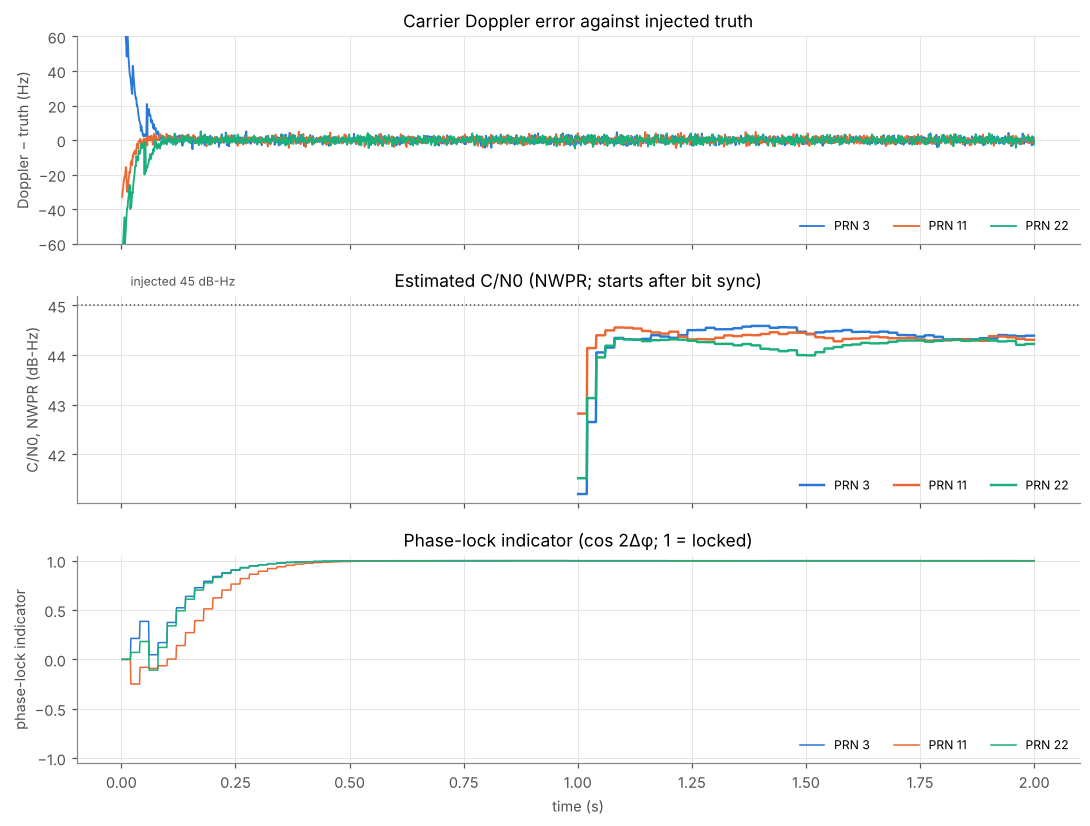

In [6]:
t0 = time.perf_counter()
trk = kshana.iq_track(I, Q, FS, "gps-l1ca", PRNS, if_hz=scene["if_hz"], acq_coherent=2)
print(f"iq_track (acq_coherent=2) over 2 s, {len(PRNS)} channels: {time.perf_counter()-t0:.1f} s")

def series(ch, key):
    return np.array([np.nan if e[key] is None else float(e[key]) for e in ch["epochs"]])

chan = {p: c for p, c in zip(PRNS, trk["channels"])}
fig, axs = plt.subplots(3, 1, figsize=(10, 7.6), sharex=True)
for p in PRNS:
    c = chan[p]
    ts = series(c, "code_epoch_s")
    axs[0].plot(ts, series(c, "doppler_hz") - truth0[p]["doppler_hz"], color=COLOR[p],
                lw=1.2, label=f"PRN {p}")
    axs[1].plot(ts, series(c, "cn0_nwpr_dbhz"), color=COLOR[p], lw=1.6, label=f"PRN {p}")
    axs[2].plot(ts, series(c, "pli"), color=COLOR[p], lw=1.0, label=f"PRN {p}")
axs[0].set(ylabel="Doppler − truth (Hz)", title="Carrier Doppler error against injected truth",
           ylim=(-60, 60))
axs[1].axhline(CN0, color=INK2, ls=":", lw=1)
axs[1].text(0.02, CN0 + 0.4, f"injected {CN0:.0f} dB-Hz", color=INK2, fontsize=8)
axs[1].set(ylabel="C/N0, NWPR (dB-Hz)", title="Estimated C/N0 (NWPR; starts after bit sync)")
axs[2].set(ylabel="phase-lock indicator", xlabel="time (s)", ylim=(-1.05, 1.05),
           title="Phase-lock indicator (cos 2Δφ; 1 = locked)")
for ax in axs:
    ax.legend(loc="lower right", ncol=3, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

In [7]:
print(f"{'PRN':>4} {'Doppler err (last 0.5 s)':>25} {'C/N0 NWPR (last 0.5 s)':>23} "
      f"{'phase lock':>11} {'code lock':>10}")
for p in PRNS:
    c = chan[p]
    ts = series(c, "code_epoch_s")
    tail = ts >= ts[-1] - 0.5
    derr = series(c, "doppler_hz")[tail] - truth0[p]["doppler_hz"]
    cn0 = series(c, "cn0_nwpr_dbhz")[tail]
    pl = np.mean([bool(e["phase_lock"]) for e, k in zip(c["epochs"], tail) if k])
    cl = np.mean([bool(e["code_lock"]) for e, k in zip(c["epochs"], tail) if k])
    print(f"{p:>4} {np.mean(derr):>+10.2f} Hz ± {np.std(derr):5.2f} {np.nanmean(cn0):>17.1f} dB-Hz "
          f"{pl:>10.0%} {cl:>10.0%}")
    assert abs(np.mean(derr)) < 5.0 and pl > 0.9 and cl > 0.9, p
    assert abs(np.nanmean(cn0) - CN0) < 2.0, p
print("\nall channels converge on the injected Doppler, hold phase and code lock, and "
      "estimate C/N0 within 2 dB")

 PRN  Doppler err (last 0.5 s)  C/N0 NWPR (last 0.5 s)  phase lock  code lock
   3      +0.01 Hz ±  1.31              44.4 dB-Hz       100%       100%
  11      +0.01 Hz ±  1.35              44.3 dB-Hz       100%       100%
  22      +0.02 Hz ±  1.37              44.2 dB-Hz       100%       100%

all channels converge on the injected Doppler, hold phase and code lock, and estimate C/N0 within 2 dB


## 5. Acquisition statistic vs C/N0

Same geometry, fresh seeded noise per level, 20 ms per scene, two searches: the default
(1 ms coherent, no non-coherent accumulation) and 1 ms coherent × 10 non-coherent. Each
statistic is compared with **its own** threshold (both set from the same false-alarm
probability), so the plot shows the statistic-to-threshold ratio averaged over the three
PRNs; a ratio above 1 (0 dB) is a detection. Longer accumulation moves the crossing down.

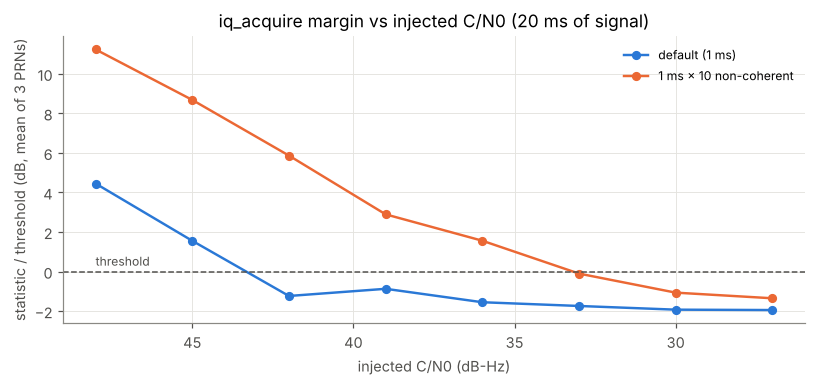

 C/N0           default (1 ms)   1 ms × 10 non-coherent
   48         +4.5 dB, 3/3 acq        +11.2 dB, 3/3 acq
   45         +1.6 dB, 3/3 acq         +8.7 dB, 3/3 acq
   42         -1.2 dB, 0/3 acq         +5.9 dB, 3/3 acq
   39         -0.9 dB, 0/3 acq         +2.9 dB, 3/3 acq
   36         -1.5 dB, 0/3 acq         +1.6 dB, 3/3 acq
   33         -1.7 dB, 0/3 acq         -0.1 dB, 2/3 acq
   30         -1.9 dB, 0/3 acq         -1.1 dB, 0/3 acq
   27         -1.9 dB, 0/3 acq         -1.3 dB, 0/3 acq


In [8]:
levels = [48, 45, 42, 39, 36, 33, 30, 27]
CONFIGS = {"default (1 ms)": {}, "1 ms × 10 non-coherent": {"noncoherent": 10}}
ratio_db = {name: [] for name in CONFIGS}
detected = {name: [] for name in CONFIGS}
for lv in levels:
    s = kshana.iq_scene(fs_hz=FS, duration_s=0.02, signal="gps-l1ca", prns=PRNS,
                        dopplers=DOPPLERS, cn0_dbhz=float(lv), seed=100 + lv)
    for name, kw in CONFIGS.items():
        a = kshana.iq_acquire(s["samples_i"], s["samples_q"], FS, "gps-l1ca", PRNS,
                              if_hz=s["if_hz"], **kw)
        ratio_db[name].append(np.mean([10 * np.log10(d["statistic"] / d["threshold"]) for d in a]))
        detected[name].append(sum(d["acquired"] for d in a))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (name, col) in zip(CONFIGS, ["#2a78d6", "#eb6834"]):
    ax.plot(levels, ratio_db[name], color=col, marker="o", ms=5, label=name)
ax.axhline(0, color=INK2, ls="--", lw=1)
ax.text(levels[0], 0.3, "threshold", color=INK2, fontsize=8)
ax.set(xlabel="injected C/N0 (dB-Hz)", ylabel="statistic / threshold (dB, mean of 3 PRNs)",
       title="iq_acquire margin vs injected C/N0 (20 ms of signal)", xlim=(49, 26))
ax.legend(fontsize=8, frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

print(f"{'C/N0':>5} " + " ".join(f"{n:>24}" for n in CONFIGS))
for k, lv in enumerate(levels):
    print(f"{lv:>5} " + " ".join(f"{ratio_db[n][k]:>+12.1f} dB, {detected[n][k]}/3 acq" for n in CONFIGS))

## Scope and limits

- **Software only.** kshana writes and reads IQ files for software receivers; it does not
  transmit or drive radio hardware, and it does not synthesise interference or spoofing
  waveforms (channel effects act on the legitimate signal only).
- **Synthetic scene.** The numbers above are truth recovery on a seeded synthetic scene. The
  receiver's agreement with external references (gps-sdr-sim, ICD tables, closed forms) is in
  the public repository's test suite at tag `v0.32.0`; see the IQ validation summary in
  `commercial/partners/` of this repository.
- **The search grid in §3 is a NumPy re-computation** for display; kshana's decision is the
  `iq_acquire` result marked on it.
- **Surfaces.** The IQ layer is on the CLI (`kshana iq …`) and Python in 0.32.0; it is not yet
  exposed in the browser/WASM build or through the MCP server.